In [5]:
import cv2
import csv
import os
import math
import torch
import numpy as np
from collections import defaultdict
from ultralytics import YOLO, RTDETR
import easyocr

# True: evalúa RT-DETR
USAR_RTDETR = False

# Configuración del rastreador para que borre objetos rápido cuando salgan de la pantalla
TRACKER_CFG = 'bytetrack_rapido.yaml'
with open(TRACKER_CFG, 'w') as f:
    f.write("""
tracker_type: bytetrack
track_high_thresh: 0.35
track_low_thresh: 0.1
new_track_thresh: 0.4
track_buffer: 8
match_thresh: 0.8
fuse_score: True
""".strip())

# Rutas de los archivos de entrada, salida y selección de tarjeta gráfica o procesador
VIDEO_ENTRADA = 'C0142.MP4'

# Nombres de salida dinámicos para evitar sobreescritura entre YOLO y RT-DETR
SUFIJO_MODELO = '_rtdetr' if USAR_RTDETR else '_yolo'
VIDEO_SALIDA = f'resultado_C0142{SUFIJO_MODELO}.mp4'
CSV_SALIDA = f'detecciones_seguimiento{SUFIJO_MODELO}.csv'

MODELO_GENERAL_PATH = 'yolo11n.pt'
MODELO_MATRICULAS_PATH = 'best_rtdetr.pt' if USAR_RTDETR else 'best.pt'

# Clases que nos interesan: personas y diferentes tipos de vehículos
CLASES_INTERES = [0, 2, 3, 5, 7]
CLASES_VEHICULOS = [2, 3, 5, 7]

DISPOSITIVO = 0 if torch.cuda.is_available() else 'cpu'
print(f"Dispositivo asignado: {DISPOSITIVO}")
print(f"Configuración activa: {'RT-DETR' if USAR_RTDETR else 'YOLO'}")
print(f"Vídeo de salida: {VIDEO_SALIDA}")
print(f"CSV de salida:   {CSV_SALIDA}")

# Carga del detector general y selección condicional del detector de matrículas
modelo_general = YOLO(MODELO_GENERAL_PATH)

if USAR_RTDETR:
    print(f"Cargando detector de matrículas RT-DETR ({MODELO_MATRICULAS_PATH})...")
    modelo_matriculas = RTDETR(MODELO_MATRICULAS_PATH)
else:
    print(f"Cargando detector de matrículas YOLO ({MODELO_MATRICULAS_PATH})...")
    modelo_matriculas = YOLO(MODELO_MATRICULAS_PATH)

# Preparación del lector de texto para las placas
print("Cargando EasyOCR...")
reader_ocr = easyocr.Reader(['es', 'en'], gpu=torch.cuda.is_available())

# Abrir el vídeo original y preparar el nuevo vídeo con los dibujos
cap = cv2.VideoCapture(VIDEO_ENTRADA)
if not cap.isOpened():
    raise FileNotFoundError(f"No se pudo abrir el video: {VIDEO_ENTRADA}")

ancho = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
alto = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)
fps_salida = fps if fps > 0 else 25.0
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

out = cv2.VideoWriter(
    VIDEO_SALIDA,
    cv2.VideoWriter_fourcc(*'mp4v'),
    fps_salida,
    (ancho, alto)
)

# Crear el archivo CSV y escribir los nombres de las columnas
f_csv = open(CSV_SALIDA, mode='w', newline='', encoding='utf-8')
csv_writer = csv.writer(f_csv)

csv_writer.writerow([
    'fotograma', 'tipo_objeto', 'confianza', 'identificador_tracking',
    'x1', 'y1', 'x2', 'y2',
    'matricula_en_su_caso', 'confianza_matricula',
    'mx1', 'my1', 'mx2', 'my2', 'texto_matricula'
])

# Filtros para evitar contar coches aparcados o detecciones que duren solo un instante
MIN_FRAMES_VALIDO = 10
MIN_DESPLAZAMIENTO = 40

# Historial para saber cuánto se mueve cada objeto y qué clase es la más votada
historial_tracks = defaultdict(lambda: {
    'inicio': None,
    'actual': None,
    'frames': 0,
    'clases': defaultdict(int)
})

# Conjuntos para registrar los identificadores únicos y no repetir el conteo
conteo_unicos = {
    'person': set(),
    'car': set(),
    'motorcycle': set(),
    'bus': set(),
    'truck': set()
}

# Memoria temporal para no repetir la lectura de matrícula en cada fotograma
cache_matriculas = {}

# Colores para dibujar las cajas según la clase
COLORES = {
    'person': (255, 105, 65),
    'car': (40, 200, 40),
    'motorcycle': (0, 165, 255),
    'bus': (200, 200, 0),
    'truck': (180, 0, 180),
    'matricula': (0, 255, 255)
}

print(f"Procesando {total_frames} fotogramas...")

# Procesar el vídeo fotograma a fotograma
frame_idx = 0
with torch.no_grad():
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
       
        frame_idx += 1

        # Detectar y seguir a personas y vehículos en la escena
        resultados_track = modelo_general.track(
            source=frame,
            persist=True,
            classes=CLASES_INTERES,
            tracker=TRACKER_CFG,
            conf=0.35,
            imgsz=640,
            device=DISPOSITIVO,
            verbose=False
        )

        # Procesar cada detección y actualizar el historial de seguimiento
        if resultados_track and len(resultados_track) > 0 and resultados_track[0].boxes is not None:
            cajas = resultados_track[0].boxes

            for box in cajas:
                x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
                confianza = float(box.conf[0])
                clase_id = int(box.cls[0])
                nombre_clase = modelo_general.names[clase_id]
                track_id = int(box.id[0]) if box.id is not None else -1

                # Descartar detecciones diminutas en el fondo
                w_box = x2 - x1
                h_box = y2 - y1
                if w_box < 25 or h_box < 25:
                    continue

                cx = int((x1 + x2) / 2)
                cy = int((y1 + y2) / 2)

                # Comprobar la trayectoria del objeto y validar si debe sumarse al total
                clase_dominante = nombre_clase
                if track_id != -1:
                    t = historial_tracks[track_id]
                    t['frames'] += 1
                    t['clases'][nombre_clase] += 1
                    if t['inicio'] is None:
                        t['inicio'] = (cx, cy)
                    t['actual'] = (cx, cy)

                    # Quedarnos con la clase que más veces haya salido
                    clase_dominante = max(t['clases'].items(), key=lambda x: x[1])[0]

                    # Validar si el objeto estuvo el tiempo mínimo y se movió lo suficiente
                    if t['frames'] >= MIN_FRAMES_VALIDO:
                        disp = math.hypot(t['actual'][0] - t['inicio'][0], t['actual'][1] - t['inicio'][1])
                        es_vehiculo = clase_id in CLASES_VEHICULOS
                       
                        if (not es_vehiculo and disp >= 20) or (es_vehiculo and disp >= MIN_DESPLAZAMIENTO):
                            for c in conteo_unicos:
                                conteo_unicos[c].discard(track_id)
                            if clase_dominante in conteo_unicos:
                                conteo_unicos[clase_dominante].add(track_id)

                caja_matricula = None
                conf_matricula = None
                texto_matricula = ""

                # Buscar la matrícula si el objeto es un vehículo
                if clase_id in CLASES_VEHICULOS:
                    vx1, vy1 = max(0, x1), max(0, y1)
                    vx2, vy2 = min(ancho, x2), min(alto, y2)
                    w_veh = vx2 - vx1
                    h_veh = vy2 - vy1

                    # Ignorar vehículos que ya estén cortados saliendo de la pantalla
                    esta_saliendo = (vx1 <= 15) or (vx2 >= ancho - 15)

                    if w_veh > 50 and h_veh > 50 and not esta_saliendo:
                        usar_detector = True

                        # Reutilizar la posición guardada de la matrícula si pasaron pocos fotogramas
                        if track_id != -1 and track_id in cache_matriculas:
                            frames_pasados = frame_idx - cache_matriculas[track_id]['frame']
                            if frames_pasados <= 4:
                                rx1, ry1, rx2, ry2 = cache_matriculas[track_id]['rel_coords']
                                gx1 = int(vx1 + rx1 * w_veh)
                                gy1 = int(vy1 + ry1 * h_veh)
                                gx2 = int(vx1 + rx2 * w_veh)
                                gy2 = int(vy1 + ry2 * h_veh)
                                caja_matricula = (gx1, gy1, gx2, gy2)
                               
                                conf_matricula = cache_matriculas[track_id].get('conf', 0.0)
                                texto_matricula = cache_matriculas[track_id].get('texto', "")
                                usar_detector = False

                        # Ejecutar el modelo de matrículas en el recorte del coche
                        if usar_detector:
                            roi_vehiculo = frame[vy1:vy2, vx1:vx2]
                            res_placas = modelo_matriculas(
                                roi_vehiculo,
                                imgsz=320,
                                conf=0.35,
                                device=DISPOSITIVO,
                                verbose=False
                            )

                            # Guardar la mejor detección de matrícula si existe
                            if res_placas and len(res_placas) > 0 and len(res_placas[0].boxes) > 0:
                                mejor_placa = res_placas[0].boxes[0]
                                px1_r, py1_r, px2_r, py2_r = map(int, mejor_placa.xyxy[0].tolist())
                               
                                gx1 = vx1 + px1_r
                                gy1 = vy1 + py1_r
                                gx2 = vx1 + px2_r
                                gy2 = vy1 + py2_r
                                caja_matricula = (gx1, gy1, gx2, gy2)
                                conf_matricula = float(mejor_placa.conf[0])

                                # Recortar y preparar la placa para leer su texto
                                img_placa = frame[gy1:gy2, gx1:gx2]
                                if img_placa.shape[0] > 10 and img_placa.shape[1] > 20:
                                   
                                    # Agrandar la imagen y pasar a grises para ver mejor los caracteres
                                    img_ampliada = cv2.resize(img_placa, None, fx=2.5, fy=2.5, interpolation=cv2.INTER_CUBIC)
                                    img_gris = cv2.cvtColor(img_ampliada, cv2.COLOR_BGR2GRAY)

                                    # Leer letras y números con EasyOCR
                                    resultados_ocr = reader_ocr.readtext(img_gris, detail=0, paragraph=True)
                                   
                                    if resultados_ocr:
                                        texto_crudo = "".join(resultados_ocr).upper()
                                        texto_limpio = "".join(filter(str.isalnum, texto_crudo))
                                       
                                        # Guardar solo si tiene una longitud lógica de matrícula
                                        if len(texto_limpio) >= 4:
                                            texto_matricula = texto_limpio

                                # Guardar la matrícula en memoria para los siguientes cuadros
                                if track_id != -1:
                                    cache_matriculas[track_id] = {
                                        'rel_coords': (px1_r / w_veh, py1_r / h_veh, px2_r / w_veh, py2_r / h_veh),
                                        'frame': frame_idx,
                                        'conf': conf_matricula,
                                        'texto': texto_matricula
                                    }
                    else:
                        # Si el coche toca el borde, borrar la matrícula de la memoria
                        if track_id != -1:
                            cache_matriculas.pop(track_id, None)

                # Guardar todos los datos calculados en la fila del CSV
                tiene_mat = "Si" if caja_matricula is not None else "No"
                conf_mat_str = f"{conf_matricula:.2f}" if caja_matricula is not None and conf_matricula is not None else ""
                mx1, my1, mx2, my2 = caja_matricula if caja_matricula is not None else ("", "", "", "")

                csv_writer.writerow([
                    frame_idx, clase_dominante, f"{confianza:.2f}", track_id,
                    x1, y1, x2, y2, tiene_mat, conf_mat_str,
                    mx1, my1, mx2, my2, texto_matricula
                ])

                # Dibujar la caja y etiqueta del vehículo o persona
                color_obj = COLORES.get(clase_dominante, (0, 255, 0))
                cv2.rectangle(frame, (x1, y1), (x2, y2), color_obj, 2)
                cv2.putText(
                    frame,
                    f"ID:{track_id} {clase_dominante}",
                    (x1, max(20, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color_obj, 2
                )

                # Dibujar la caja amarilla y el texto de la matrícula si existe
                if caja_matricula is not None:
                    cv2.rectangle(frame, (mx1, my1), (mx2, my2), COLORES['matricula'], 2)
                    etiqueta_placa = f"{texto_matricula} ({conf_mat_str})" if texto_matricula else "Matricula"
                    cv2.putText(
                        frame, etiqueta_placa,
                        (mx1, max(15, my1 - 5)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.45, COLORES['matricula'], 2
                    )

        # Panel informativo en la esquina superior con los conteos acumulados
        cv2.rectangle(frame, (15, 15), (270, 160), (0, 0, 0), -1)
        cv2.rectangle(frame, (15, 15), (270, 160), (255, 255, 255), 1)
        cv2.putText(frame, f"Frame: {frame_idx}/{total_frames}", (25, 38), cv2.FONT_HERSHEY_SIMPLEX, 0.52, (255, 255, 255), 1)

        y_offset = 62
        for clase, ids in conteo_unicos.items():
            color_txt = COLORES.get(clase, (200, 200, 200))
            cv2.putText(frame, f"Total {clase}s: {len(ids)}", (25, y_offset), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color_txt, 1)
            y_offset += 22

        # Grabar el fotograma con los dibujos en el vídeo final
        out.write(frame)
        if frame_idx % 50 == 0 or frame_idx == total_frames:
            print(f"Progreso: {frame_idx}/{total_frames} fotogramas procesados...")

# Cerrar el vídeo, el archivo de datos y mostrar confirmación final
cap.release()
out.release()
f_csv.close()

print(f"\n¡Procesamiento finalizado con éxito ({'RT-DETR' if USAR_RTDETR else 'YOLO'})!")
print(f"Vídeo generado: {VIDEO_SALIDA}")
print(f"CSV generado:   {CSV_SALIDA}")

Dispositivo asignado: cpu
Configuración activa: YOLO
Vídeo de salida: resultado_C0142_yolo.mp4
CSV de salida:   detecciones_seguimiento_yolo.csv


Using CPU. Note: This module is much faster with a GPU.


Cargando detector de matrículas YOLO (best.pt)...
Cargando EasyOCR...
Procesando 2832 fotogramas...
Progreso: 50/2832 fotogramas procesados...
Progreso: 100/2832 fotogramas procesados...
Progreso: 150/2832 fotogramas procesados...
Progreso: 200/2832 fotogramas procesados...
Progreso: 250/2832 fotogramas procesados...
Progreso: 300/2832 fotogramas procesados...
Progreso: 350/2832 fotogramas procesados...
Progreso: 400/2832 fotogramas procesados...
Progreso: 450/2832 fotogramas procesados...
Progreso: 500/2832 fotogramas procesados...
Progreso: 550/2832 fotogramas procesados...
Progreso: 600/2832 fotogramas procesados...
Progreso: 650/2832 fotogramas procesados...
Progreso: 700/2832 fotogramas procesados...
Progreso: 750/2832 fotogramas procesados...
Progreso: 800/2832 fotogramas procesados...
Progreso: 850/2832 fotogramas procesados...
Progreso: 900/2832 fotogramas procesados...
Progreso: 950/2832 fotogramas procesados...
Progreso: 1000/2832 fotogramas procesados...
Progreso: 1050/2832 

cargando modelos yolo...


Using CPU. Note: This module is much faster with a GPU.


cargando modelo ocr clásico...
cargando modelo vlm...


c:\Users\HP\anaconda3\envs\VC_P4\lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(



iniciando procesamiento de 60 imágenes...
[1/60] 0019GVM.jpg -> leyendo texto...


c:\Users\HP\anaconda3\envs\VC_P4\lib\site-packages\torch\utils\data\dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
c:\Users\HP\anaconda3\envs\VC_P4\lib\site-packages\transformers\generation\configuration_utils.py:453: UserWarning: `num_beams` is set to 1. However, `early_stopping` is set to `True` -- this flag is only used in beam-based generation modes. You should set `num_beams>1` or unset `early_stopping`.
  warnings.warn(


[2/60] 0083CPC.jpg -> leyendo texto...
[3/60] 0239GLK.jpg -> leyendo texto...
[4/60] 0310RCU.jpg -> leyendo texto...
[5/60] 0478LFR.jpg -> leyendo texto...
[6/60] 0523HNF.jpg -> leyendo texto...
[7/60] 0635LYZ.jpg -> leyendo texto...
[8/60] 0674BZH.jpg -> matrícula no detectada.
[9/60] 0802HFP.jpg -> leyendo texto...
[10/60] 0849GSD.jpg -> leyendo texto...
[11/60] 1049LDV.jpg -> leyendo texto...
[12/60] 1104CZK.jpg -> leyendo texto...
[13/60] 1159FPG.jpg -> leyendo texto...
[14/60] 1268CDN.jpg -> leyendo texto...
[15/60] 1319FSX.jpg -> leyendo texto...
[16/60] 1336LFG.jpg -> leyendo texto...
[17/60] 2021AXP.jpg -> leyendo texto...
[18/60] 220LNW.jpg -> leyendo texto...
[19/60] 2496BMT.jpg -> leyendo texto...
[20/60] 2711LKN.jpg -> matrícula no detectada.
[21/60] 2942HFB.jpg -> leyendo texto...
[22/60] 3027LMJ.jpg -> leyendo texto...
[23/60] 3685HDP.jpg -> vehículo no detectado.
[24/60] 3821GYG.jpg -> matrícula no detectada.
[25/60] 3838KWB.jpg -> leyendo texto...
[26/60] 4041LHK.jpg ->

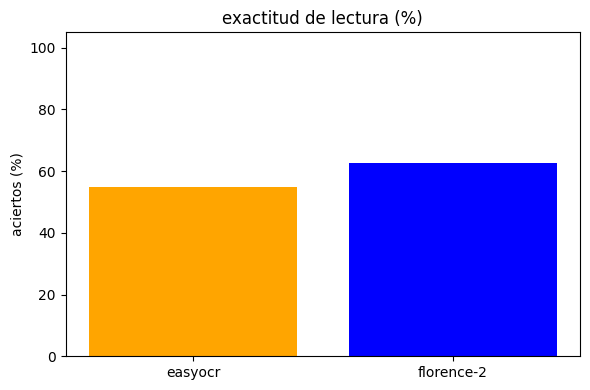

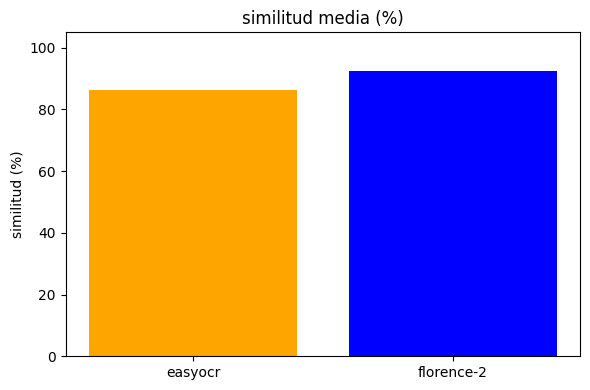

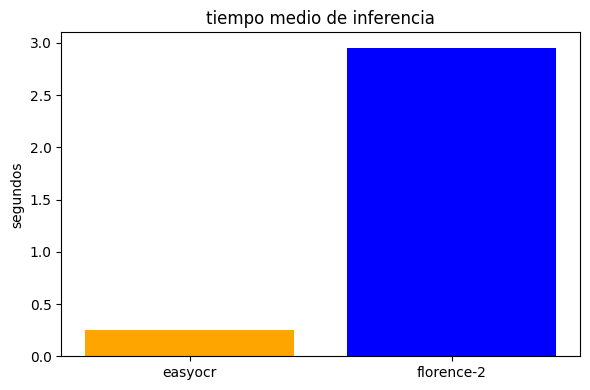

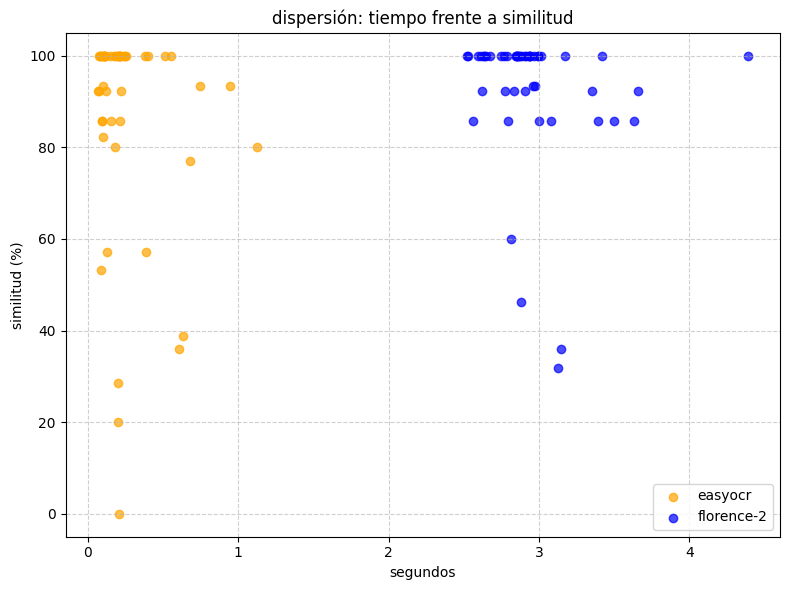

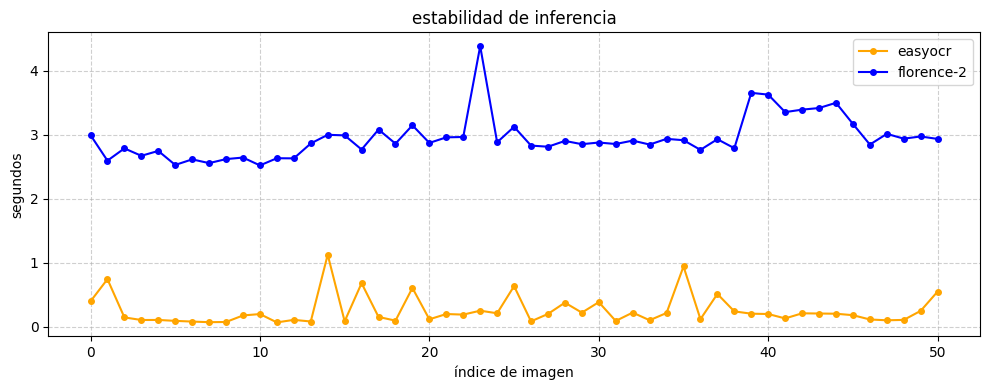

In [2]:
import sys
import types
import importlib.machinery
import os
import time
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import torch
import easyocr
import difflib
from transformers import AutoProcessor, AutoModelForCausalLM
from PIL import Image
from ultralytics import YOLO

# parche para dependencias en windows
dummy_flash = types.ModuleType('flash_attn')
dummy_flash.__spec__ = importlib.machinery.ModuleSpec('flash_attn', None)
sys.modules['flash_attn'] = dummy_flash
sys.modules['flash_attn.bert_padding'] = dummy_flash

# calcula similitud entre cadenas de texto
def calculate_similarity(read_text, true_text):
    if not read_text or not true_text:
        return 0.0
    return difflib.SequenceMatcher(None, read_text, true_text).ratio() * 100

image_folder = "./fotos_prueba"
csv_output = "resultados_comparativa.csv"
vehicle_classes = [2, 3, 5, 7]

print("cargando modelos yolo...")
vehicle_model = YOLO('yolo11n.pt')
plate_model = YOLO('best.pt')

print("cargando modelo ocr clásico...")
use_gpu = torch.cuda.is_available()
ocr_reader = easyocr.Reader(['es', 'en'], gpu=use_gpu)

print("cargando modelo vlm...")
device = "cuda:0" if use_gpu else "cpu"
tensor_dtype = torch.float16 if use_gpu else torch.float32

vlm_processor = AutoProcessor.from_pretrained("microsoft/Florence-2-base", trust_remote_code=True)
vlm_model = AutoModelForCausalLM.from_pretrained("microsoft/Florence-2-base", torch_dtype=tensor_dtype, trust_remote_code=True).to(device)

if not os.path.exists(image_folder):
    print("carpeta de imágenes no encontrada.")
    sys.exit()

image_files = [f for f in os.listdir(image_folder) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
total_images = len(image_files)
results_list = []

print(f"\niniciando procesamiento de {total_images} imágenes...")

for index, file_name in enumerate(image_files, 1):
    true_plate_text = file_name.split('.')[0].upper()
    image_path = os.path.join(image_folder, file_name)
    frame = cv2.imread(image_path)
    
    print(f"[{index}/{total_images}] {file_name}", end=" -> ")
    
    if frame is None:
        print("error de lectura.")
        continue

    # detección de vehículo
    vehicle_detections = vehicle_model(frame, classes=vehicle_classes, conf=0.25, verbose=False)
    if not vehicle_detections[0].boxes or len(vehicle_detections[0].boxes) == 0:
        print("vehículo no detectado.")
        continue

    vx1, vy1, vx2, vy2 = map(int, vehicle_detections[0].boxes[0].xyxy[0])
    vehicle_crop = frame[vy1:vy2, vx1:vx2]

    # detección de matrícula
    plate_detections = plate_model(vehicle_crop, conf=0.25, verbose=False)
    if not plate_detections[0].boxes or len(plate_detections[0].boxes) == 0:
        print("matrícula no detectada.")
        continue

    print("leyendo texto...")

    px1, py1, px2, py2 = map(int, plate_detections[0].boxes[0].xyxy[0])
    h, w = vehicle_crop.shape[:2]
    
    # recorte con margen
    plate_crop = vehicle_crop[max(0, py1 - 5):min(h, py2 + 5), max(0, px1 - 5):min(w, px2 + 5)]
    if plate_crop.size == 0:
        continue

    plate_pil_image = Image.fromarray(cv2.cvtColor(plate_crop, cv2.COLOR_BGR2RGB))

    # lectura con easyocr
    start_time = time.time()
    gray_plate = cv2.cvtColor(plate_crop, cv2.COLOR_BGR2GRAY)
    ocr_output = ocr_reader.readtext(gray_plate, detail=0, paragraph=True)
    easyocr_time = time.time() - start_time
    
    easyocr_text = "".join(filter(str.isalnum, "".join(ocr_output).upper()))

    # lectura con florence-2
    start_time = time.time()
    prompt = "<OCR>"
    vlm_inputs = vlm_processor(text=prompt, images=plate_pil_image, return_tensors="pt").to(device, tensor_dtype)
    
    with torch.no_grad():
        generated_ids = vlm_model.generate(
            input_ids=vlm_inputs["input_ids"],
            pixel_values=vlm_inputs["pixel_values"],
            max_new_tokens=64,
            do_sample=False,
            num_beams=1
        )
    generated_text = vlm_processor.batch_decode(generated_ids, skip_special_tokens=False)[0]
    vlm_time = time.time() - start_time
    
    vlm_parsed = vlm_processor.post_process_generation(generated_text, task=prompt, image_size=(plate_pil_image.width, plate_pil_image.height))
    vlm_text = "".join(filter(str.isalnum, vlm_parsed[prompt].upper().replace(" ", "")))

    # almacenar iteración
    results_list.append({
        'filename': file_name,
        'true_plate': true_plate_text,
        'easyocr_text': easyocr_text,
        'easyocr_time': easyocr_time,
        'easyocr_similarity': calculate_similarity(easyocr_text, true_plate_text),
        'vlm_text': vlm_text,
        'vlm_time': vlm_time,
        'vlm_similarity': calculate_similarity(vlm_text, true_plate_text)
    })

# análisis de resultados
df_results = pd.DataFrame(results_list)
df_results.to_csv(csv_output, index=False)

processed_count = len(df_results)
if processed_count == 0:
    print("no hay datos para analizar.")
    sys.exit()

easyocr_matches = (df_results['easyocr_text'] == df_results['true_plate']).sum()
vlm_matches = (df_results['vlm_text'] == df_results['true_plate']).sum()

easyocr_accuracy = (easyocr_matches / processed_count) * 100
vlm_accuracy = (vlm_matches / processed_count) * 100

easyocr_avg_sim = df_results['easyocr_similarity'].mean()
vlm_avg_sim = df_results['vlm_similarity'].mean()

easyocr_avg_time = df_results['easyocr_time'].mean()
vlm_avg_time = df_results['vlm_time'].mean()

print("\nresumen de rendimiento")
print(f"imágenes válidas: {processed_count}")
print(f"easyocr -> exactitud: {easyocr_accuracy:.1f}%, similitud: {easyocr_avg_sim:.1f}%, tiempo: {easyocr_avg_time:.3f}s")
print(f"vlm     -> exactitud: {vlm_accuracy:.1f}%, similitud: {vlm_avg_sim:.1f}%, tiempo: {vlm_avg_time:.3f}s")

# generación de gráficas
model_names = ['easyocr', 'florence-2']
bar_colors = ['orange', 'blue']

plt.figure(figsize=(6, 4))
plt.bar(model_names, [easyocr_accuracy, vlm_accuracy], color=bar_colors)
plt.title('exactitud de lectura (%)')
plt.ylabel('aciertos (%)')
plt.ylim(0, 105)
plt.tight_layout()
plt.savefig('grafica_1_precision.png')

plt.figure(figsize=(6, 4))
plt.bar(model_names, [easyocr_avg_sim, vlm_avg_sim], color=bar_colors)
plt.title('similitud media (%)')
plt.ylabel('similitud (%)')
plt.ylim(0, 105)
plt.tight_layout()
plt.savefig('grafica_2_similitud.png')

plt.figure(figsize=(6, 4))
plt.bar(model_names, [easyocr_avg_time, vlm_avg_time], color=bar_colors)
plt.title('tiempo medio de inferencia')
plt.ylabel('segundos')
plt.tight_layout()
plt.savefig('grafica_3_tiempo.png')

plt.figure(figsize=(8, 6))
plt.scatter(df_results['easyocr_time'], df_results['easyocr_similarity'], color='orange', label='easyocr', alpha=0.7)
plt.scatter(df_results['vlm_time'], df_results['vlm_similarity'], color='blue', label='florence-2', alpha=0.7)
plt.title('dispersión: tiempo frente a similitud')
plt.xlabel('segundos')
plt.ylabel('similitud (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('grafica_4_dispersion.png')

plt.figure(figsize=(10, 4))
plt.plot(df_results.index, df_results['easyocr_time'], color='orange', label='easyocr', marker='o', markersize=4)
plt.plot(df_results.index, df_results['vlm_time'], color='blue', label='florence-2', marker='o', markersize=4)
plt.title('estabilidad de inferencia')
plt.xlabel('índice de imagen')
plt.ylabel('segundos')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('grafica_5_estabilidad.png')

print("\nproceso completado. gráficas guardadas.")